In [ ]:
def interpolate_small_yjumps(series, max_jump): # Moved to Functions.ipynb
    before = series.ffill() # fills missing values using forward fill, where the last valid observation is propagated forward to fill the gaps.
    after = series.bfill() # fills missing values in a backward direction along the specified axis, propagating non-null values from later positions to earlier positions containing NaN.
    fill_allowed = series.isna() & ((after - before).abs() < max_jump) # Fill is allowed if the value is a nan and the difference between the start and end of the fill is less than the maximum y difference
    interpolated = series.interpolate(method="time") # Fill NaN values using an interpolation method. ‘time’: Works on daily and higher resolution data to interpolate given length of interval. This interpolates values based on time interval between observations.
    return series.where(~fill_allowed, interpolated)

    
# def interpolate_small_xjumps(series, max_jump): # Moved to Functions.ipynb
#     # seriesNoNans = series.dropna() # drop nans to get adjacent time indexs
#     # timeDiff = seriesNoNans.index - seriesNoNans.index.shift() # check time between indexes - gets time difference but not sure how to apply to correct series values

#     # series["times"] = series.index#.to_julian_date() # get time indexes
#     # series["deltat"] = series - series.shift() # calculate time shift (always one minute for minutely data - how to reference "nonnan before and nonnan after")
#     # series["deltat"] = series["times"] - series["times"].shift() # 

#     series["times"] = series.index # get times
#     series["deltat"] = series.dropna().diff() # get differences between times ignoring nans
#     print(series["deltat"]) # print to check
    
#     fill_allowed = series.isna() & series["deltat"] < max_jump # need to compare maxjump to the correct deltat, but now the dataframes are difference lengths

#     interpolated = series.interpolate(method="time") # Fill NaN values using an interpolation method. ‘time’: Works on daily and higher resolution data to interpolate given length of interval. This interpolates values based on time interval between observations.
#     return series.where(~fill_allowed, interpolated)

# help from Laura
def interpolate_small_time_gaps(series, max_gap):
    times = pd.Series(series.index, index=series.index) # make array called times that has the index as the values
    print(times)
    valid_times = times.where(series.notna()) # where the values are not nans in the series data, keep the times, where they are, make them nans
    print(valid_times)
    gap = valid_times.bfill() - valid_times.ffill() # calculate the gap by back and forwards filling the nan times in valid_times
    print(gap)
    fill_allowed = series.isna() & (gap <= max_gap) # allow a fill when the value is nan and the gap is less than the maximum gap
    interpolated = series.interpolate(method="time", limit_area="inside") # interpolate, ‘inside’: Only fill NaNs surrounded by valid values (interpolate).
    return series.where(~fill_allowed, interpolated) # return interpolated dataframe

2021-01-01 00:00:00   2021-01-01 00:00:00
2021-01-01 00:01:00   2021-01-01 00:01:00
2021-01-01 00:02:00   2021-01-01 00:02:00
2021-01-01 00:03:00   2021-01-01 00:03:00
2021-01-01 00:04:00   2021-01-01 00:04:00
2021-01-01 00:05:00   2021-01-01 00:05:00
2021-01-01 00:06:00   2021-01-01 00:06:00
2021-01-01 00:07:00   2021-01-01 00:07:00
2021-01-01 00:08:00   2021-01-01 00:08:00
2021-01-01 00:09:00   2021-01-01 00:09:00
2021-01-01 00:10:00   2021-01-01 00:10:00
2021-01-01 00:11:00   2021-01-01 00:11:00
2021-01-01 00:12:00   2021-01-01 00:12:00
2021-01-01 00:13:00   2021-01-01 00:13:00
2021-01-01 00:14:00   2021-01-01 00:14:00
2021-01-01 00:15:00   2021-01-01 00:15:00
2021-01-01 00:16:00   2021-01-01 00:16:00
2021-01-01 00:17:00   2021-01-01 00:17:00
2021-01-01 00:18:00   2021-01-01 00:18:00
2021-01-01 00:19:00   2021-01-01 00:19:00
2021-01-01 00:20:00   2021-01-01 00:20:00
2021-01-01 00:21:00   2021-01-01 00:21:00
2021-01-01 00:22:00   2021-01-01 00:22:00
2021-01-01 00:23:00   2021-01-01 0

<Axes: >

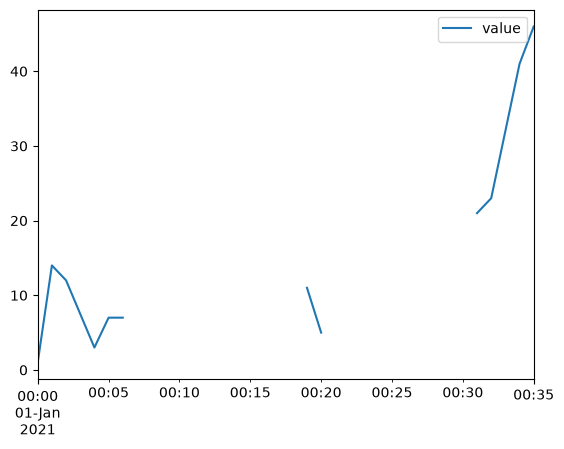

In [101]:
df = pd.DataFrame(
    { "value": [ 1, 14, 12, np.nan, 3, 7, 7, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, 11, 5, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, 21, 23, np.nan, 41, 46 ] },
    index=pd.to_datetime( [ 
        "2021-01-01 00:00", "2021-01-01 00:01", "2021-01-01 00:02",
        "2021-01-01 00:03", "2021-01-01 00:04", "2021-01-01 00:05",
        "2021-01-01 00:06", "2021-01-01 00:07", "2021-01-01 00:08",
        "2021-01-01 00:09", "2021-01-01 00:10", "2021-01-01 00:11",
        "2021-01-01 00:12", "2021-01-01 00:13", "2021-01-01 00:14",
        "2021-01-01 00:15", "2021-01-01 00:16", "2021-01-01 00:17",
        "2021-01-01 00:18", "2021-01-01 00:19", "2021-01-01 00:20",
        "2021-01-01 00:21", "2021-01-01 00:22", "2021-01-01 00:23",
        "2021-01-01 00:24", "2021-01-01 00:25", "2021-01-01 00:26",
        "2021-01-01 00:27", "2021-01-01 00:28", "2021-01-01 00:29",
        "2021-01-01 00:30", "2021-01-01 00:31", "2021-01-01 00:32",
        "2021-01-01 00:33", "2021-01-01 00:34", "2021-01-01 00:35",
    ] )
)
# print(df)
# print(df.shift())
# df['tvalue'] = df.index
# # print(df['tvalue'] - df['tvalue'].shift())
# df["deltat"] = df['tvalue'] - df['tvalue'].shift()
# print(df["deltat"])

# df["times"] = df.index
# df["dataTimes"] = df["value"].fillna(df["times"])
# print(df)
# df["deltat"] = df.dropna().index.diff() # fill the nans with the values either side
# print(df["deltat"])

# Times = df.dropna().index.diff() # fill the nans with the values either side
# print(Times)

# df.plot()

# from datetime import datetime, timedelta
interpolateXJump = timedelta(minutes = 10)
# print(interpolateXJump)

dfInterpolated = df.sort_index().apply(interpolate_small_time_gaps, max_gap=interpolateXJump) #np.sqrt(varThres))

print(dfInterpolated)
dfInterpolated.plot()


In [52]:
import pandas as pd
import numpy as np

df = pd.DataFrame(
    { "value": [ 1, np.nan, 3, np.nan, np.nan, 5, np.nan, 11, np.nan, 21, np.nan, 41 ] },
    index=pd.to_datetime( [ 
        "2021-01-01 00:00", "2021-01-01 00:05", "2021-01-01 00:10",
        "2021-01-01 00:11", "2021-01-01 00:13", "2021-01-01 00:14",
        "2021-01-01 00:15", "2021-01-01 01:30", "2021-01-01 03:00",
        "2021-01-01 04:00", "2021-01-01 05:45", "2021-01-01 06:45",
    ] )
)

jd_max_gap_fill = 5/(60*24) # Got equivalent

df['ffill'] = df['value'].ffill() # Got equivalent
df['value_gap'] = df['value'].bfill() - df['value'].ffill() # don't need I think

df['jd'] = df.index.to_julian_date()  # don't need I think

df['jd_nan'] = np.where(~df['value'].isna(), df['jd'], np.nan)
df['jd_gap'] = df['jd_nan'].bfill() - df['jd_nan'].ffill()

df['jd_start'] = df['jd_nan'].ffill() 
df['jd_prp'] = np.where(df['jd_gap'] != 0, (df['jd'] - df['jd_start'])/df['jd_gap'], 0)

df['filled_value'] = np.where(df['jd_gap'] <= jd_max_gap_fill, df['ffill'] + df['value_gap'] * df['jd_prp'], np.nan) 

df['filled_value']


max_jump = 10 # 10 minutes
# before = series.ffill() # fills missing values using forward fill, where the last valid observation is propagated forward to fill the gaps.
# after = series.bfill() # fills missing values in a backward direction along the specified axis, propagating non-null values from later positions to earlier positions containing NaN.


fill_allowed = series.isna() & ((series.index[] - series.index).abs() < max_jump) # Fill is allowed if the value is a nan and the difference between the start and end of the fill is less than the maximum y difference

interpolated = series.interpolate(method="time") # Fill N




SyntaxError: invalid syntax. Perhaps you forgot a comma? (219277346.py, line 37)